# MapReduce-Reloaded: a tour of the features

*The programming model and the machinery under it, run on one machine in a
few seconds. Every claim below is checked with an `assert` as the notebook
runs, and a scorecard at the end gathers what held.*

This notebook is the companion to [`demo.ipynb`](demo.ipynb). The demo runs
the system live on a coordinator and four workers and puts it through its
faults: a worker killed mid-job, the coordinator restarted mid-job. This one
needs no cluster and no Docker. It runs every job in this process with the
library's local mode, so it can show the parts the demo goes past quickly:
how a program is written, why its answer cannot depend on how the work is
split, and the file formats, sorter and log that the cluster is built on.

| § | What it shows | Paper |
|---|---|---|
| 1 | Setup: a temporary directory, the helpers | |
| 2 | Word count in two small functions, checked against the golden output | §2 |
| 3 | The answer does not depend on M, the number of map tasks | §3.3 |
| 4 | Partitioning: which reduce task gets each key, and sorted keys within it | §4.1, §4.2 |
| 5 | The combiner: far fewer bytes shuffled, the same answer | §4.3 |
| 6 | Counters, job parameters and side outputs | §4.5, §4.9 |
| 7 | Seven programs, one model: every example against its golden output | §2.3, §5.3 |
| 8 | The MRKV record format: three codecs, and a checksum that catches damage | |
| 9 | Sorting more data than fits in memory | §3.1 |
| 10 | The write-ahead log: a torn tail is dropped, real damage is refused | beyond the paper |
| 11 | Go and Python agree byte for byte, a Go job file included | |
| 12 | Scorecard and clean up | |

**How to run it.** From the repository root, with the Python package
installed (`pip install -e 'python[compression,notebook]'` in `python/.venv`):

```sh
python/.venv/bin/jupyter notebook examples/features.ipynb
# or every cell, without a browser:
python/.venv/bin/jupyter nbconvert --to notebook --execute --inplace examples/features.ipynb
```

It takes a few seconds. Section 11 also needs the Go client: it uses
`bin/mr` if `make mr` has built it, or builds it into the temporary directory
if Go is installed; without either, that section is skipped and the
scorecard says so.

**Safe beside the demo.** Everything this notebook writes goes into one new
temporary directory, which the last cell removes. It never touches `data/`,
the cluster, or the `notebook-*` paths the demo cleans up, so you can run it
before, after or while the demo runs.

---

## 1. Setup

The setup cell finds the repository, makes a fresh temporary directory for
everything this run writes, and defines a few helpers: `job()` runs a
program with the library's local mode and returns its counters, `output()`
reads a job's part files back as bytes, and `passed()` records a claim for
the scorecard. Figures are drawn when matplotlib is installed and skipped
when it is not; every check runs either way. No path on this machine is
printed, so the saved outputs read the same anywhere.

In [1]:
import importlib
import io
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path

from IPython.display import Markdown, display

try:  # the figures are optional: every check runs without matplotlib
    import matplotlib.pyplot as plt
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    set_matplotlib_formats("retina")
    HAVE_PLOT = True
except ImportError:
    HAVE_PLOT = False

# Section 11 builds the Go client into this run's temporary directory when
# bin/mr is missing and Go is installed. False skips the build.
BUILD_MR = True


def find_root():
    """The repository root: MR_ROOT, or the first of the kernel's working
    directory and its parents that holds testdata/corpus. Jupyter starts
    the kernel in examples/, the notebook's directory."""
    if "MR_ROOT" in os.environ:
        return Path(os.environ["MR_ROOT"])
    for path in (Path.cwd(), *Path.cwd().parents):
        if (path / "testdata" / "corpus" / "expected").is_dir():
            return path
    raise RuntimeError("not inside the repository: set MR_ROOT to its path")


ROOT = find_root()
try:
    import mapreduce_reloaded  # noqa: F401
except ImportError:  # not installed: use the checkout's copy
    sys.path.insert(0, str(ROOT / "python"))

from mapreduce_reloaded import extsort, local, wal  # noqa: E402
from mapreduce_reloaded.api import JobSpec, Program, mapper, reducer  # noqa: E402
from mapreduce_reloaded.formats import kv  # noqa: E402
from mapreduce_reloaded.partition.hash import fnv1a64, partition  # noqa: E402

WORK = Path(tempfile.mkdtemp(prefix="mr-features-"))  # everything this run writes
CORPUS = ("testdata/corpus/*.txt",)  # five public-domain books, 460 KB
EXPECTED = b"".join(p.read_bytes() for p in sorted((ROOT / "testdata/corpus/expected").glob("part-r-*")))
CHECKS = {}  # each claim a section checked, by section and claim, for the scorecard
# The project's chart colors (bench/plot-experiments.py): blue is the
# system as shipped, orange the changed condition, text in ink, not color.
BLUE, ORANGE, INK, INK2 = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"


def job(program, name, inputs=CORPUS, r=4, **options):
    """Runs program over inputs (paths or globs relative to the repository
    root) with local mode, R = r, into WORK/name, and returns its counters
    and the time it took in seconds."""
    scratch = WORK / f"{name}.tmp"
    scratch.mkdir()
    spec = JobSpec(program=program, inputs=tuple(str(ROOT / p) for p in inputs),
                   output=str(WORK / name), r=r, **options)
    start = time.perf_counter()
    counters = local.run(spec, str(scratch))
    seconds = time.perf_counter() - start
    shutil.rmtree(scratch)
    return counters, seconds


def parts(name):
    """A job's part files, in order."""
    return sorted((WORK / name).glob("part-r-*"))


def output(name):
    """A job's output, its part files in order, as bytes."""
    return b"".join(p.read_bytes() for p in parts(name))


def table(header, rows):
    """Shows rows as a Markdown table, which Jupyter renders."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def caption(number, text):
    """Captions the figure just shown, numbered in the order they appear."""
    display(Markdown(f"**Figure {number}.** {text}"))


def style(axis, title):
    """The project's chart style: a left-aligned finding as the title,
    hairline axes, no box."""
    axis.set_title(title, loc="left", fontsize=11, color=INK)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color("#c3c2b7")
    axis.tick_params(colors="#c3c2b7", labelcolor=INK2)


def check_key(section, claim):
    """A claim's scorecard key: its section and its words before any colon,
    which hold measured values that change between runs. Running a section
    again replaces its row instead of adding a second one."""
    return section, claim.split(":", 1)[0]


def passed(section, claim):
    """Records a claim whose asserts just held, for the scorecard, and says so."""
    CHECKS[check_key(section, claim)] = (claim, "✓ held")
    print(f"✓ {claim}")


def pending(section, claim):
    """Records a claim its section is about to test: a section that stops
    on an error leaves it marked as not held, not an earlier run's result."""
    CHECKS[check_key(section, claim)] = (claim, "✗ did not finish")


def skipped(section, claim, reason):
    """Records a claim this run could not test, and why."""
    CHECKS[check_key(section, claim)] = (claim, f"skipped ({reason}): not tested")
    print(f"skipped ({reason}): {claim}")


print(f"ready: the repository's testdata, a new temporary directory for this run;"
      f" figures {'on' if HAVE_PLOT else 'off (matplotlib is not installed)'}")

ready: the repository's testdata, a new temporary directory for this run; figures on


---

## 2. The programming model: word count in two functions

The paper's promise is that a program is two small functions. `Map` reads
one record, here a line of text with its byte offset as the key, and emits
pairs; `Reduce` receives one key with every value emitted for it and emits
the result. Keys and values are bytes, so the program chooses its own
encoding. The framework does everything in between: splitting the input,
grouping the pairs by key, and sorting.

The cell writes word count exactly that way and runs it over five books
with R = 4 reduce tasks. Its output is four part files, which together must
equal `testdata/corpus/expected` byte for byte: the same golden output the
Go tests, the Python tests and the demo's cluster all check against.

In [2]:
@mapper
def words(ctx, offset, line):
    for word in line.split():
        yield word, b"1"


@reducer
def total(ctx, word, counts):
    yield word, b"%d" % sum(int(c) for c in counts)


WORDCOUNT = Program(mapper=words, reducer=total)
counters, seconds = job(WORDCOUNT, "wordcount")
assert output("wordcount") == EXPECTED, "word count differs from testdata/corpus/expected"

COUNTS = {}
for line in output("wordcount").splitlines():
    word, n = line.rsplit(b"\t", 1)
    COUNTS[word] = int(n)
top = sorted(COUNTS.items(), key=lambda item: (-item[1], item[0]))[:8]
table(["Word", "Count"], [(f"`{w.decode()}`", f"{n:,}") for w, n in top])
table(["Counter", "Value"], [(name, f"{value:,}") for name, value in sorted(counters.items())])
passed(2, f"Two functions count {len(COUNTS):,} distinct words and match the golden output: {seconds:.2f} s")

| Word | Count |
|---|---|
| `the` | 3,444 |
| `and` | 1,817 |
| `of` | 1,713 |
| `to` | 1,436 |
| `a` | 1,356 |
| `in` | 1,088 |
| `I` | 878 |
| `was` | 857 |

| Counter | Value |
|---|---|
| map.input.bytes | 461,826 |
| map.input.records | 9,316 |
| map.output.bytes | 606,019 |
| map.output.records | 78,658 |
| reduce.input.records | 78,658 |
| reduce.output.bytes | 142,296 |
| reduce.output.records | 16,851 |

✓ Two functions count 16,851 distinct words and match the golden output: 0.45 s


---

## 3. The answer does not depend on M

How finely the input is split is the framework's choice, not the program's:
M map tasks can run anywhere, in any order, and any of them can be run
again. The paper's §3.3 says that a deterministic program's output is the
same as a sequential run's, however the work was divided and retried. Here we hold the program and R fixed and
request 1, 4 and 16 map tasks. M is a request: every non-empty input file
gets at least one task, so over the corpus's four files the first two
requests both run four, and the table shows the count the planner chose.

Point at two columns. The output's digest is the same in every row. The
bytes the map tasks emit are not: this run uses the library's word count,
which has a combiner (section 5), and a combiner can only merge what one
map task sees, so more, smaller tasks leave more pairs unmerged. The work
changes with M; the answer does not.

In [3]:
import hashlib

wordcount = importlib.import_module("mapreduce_reloaded.examples.wordcount").program
rows = []
text = local.input_format("text")
for m in (1, 4, 16):
    tasks = len(local.plan_m(text, [str(ROOT / p) for p in CORPUS], m))  # what the planner makes of m
    counters, seconds = job(wordcount, f"m{m}", m=m)
    got = output(f"m{m}")
    assert got == EXPECTED, f"M = {m} changed the output"
    rows.append((m, tasks, f"{counters['map.output.bytes']:,}", hashlib.sha256(got).hexdigest()[:12], f"{seconds:.2f}"))
table(["Requested M", "Map tasks", "Map output bytes", "Output SHA-256", "Seconds"], rows)
passed(3, "Requested M = 1, 4 and 16 give byte-identical output")

| Requested M | Map tasks | Map output bytes | Output SHA-256 | Seconds |
|---|---|---|---|---|
| 1 | 4 | 197,618 | 05038a2c4c30 | 0.32 |
| 4 | 4 | 197,618 | 05038a2c4c30 | 0.30 |
| 16 | 16 | 275,997 | 05038a2c4c30 | 0.41 |

✓ Requested M = 1, 4 and 16 give byte-identical output


---

## 4. Partitioning: which reduce task gets each key

Every map task must send all the pairs for one key to the same reduce task,
without asking anyone. The default partitioner does it with a hash, as §4.1
describes: `hash(key) mod R`, where the hash is 64-bit FNV-1a, the same in
Go and Python so both implementations place every key alike. Within each
reduce task, §4.2 promises keys in sorted order.

The cell reads section 2's four part files back and checks both promises
for every one of the distinct words: each sits in part `partition(key, 4)`,
and each part's keys are in increasing byte order. A hash spreads the keys
evenly, which the figure shows.

| Key | FNV-1a 64 | mod 4 |
|---|---|---|
| `the` | 0x56f5c9194461d57c | 0 |
| `whale` | 0x132fdb887ec5ad96 | 2 |
| `Raven` | 0xcdc35e77fe21c9bd | 1 |

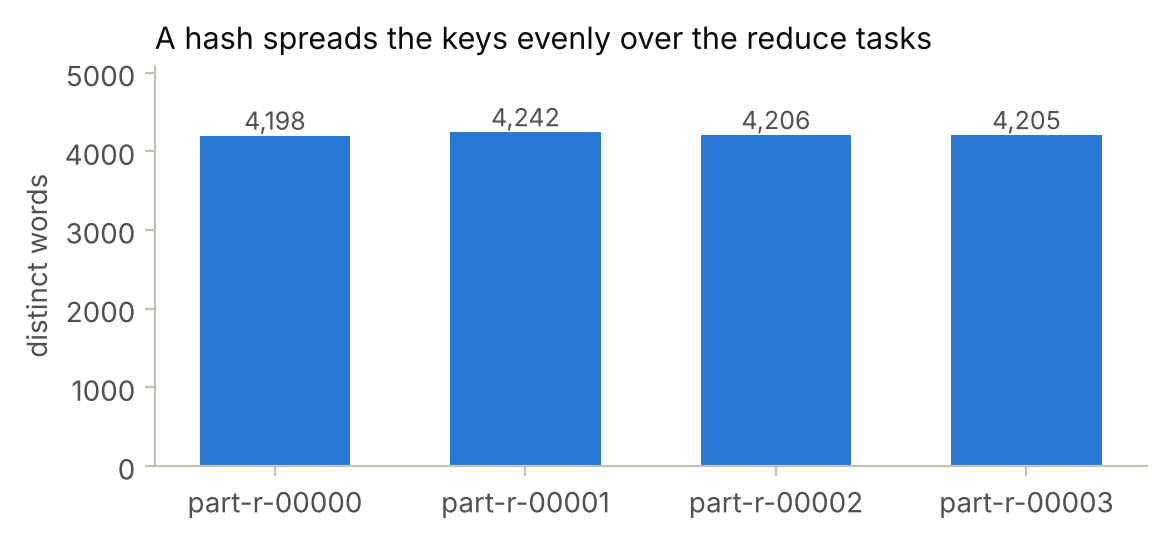

**Figure 1.** Distinct words in each of section 2's four part files.

✓ Every key is in part hash(key) mod R, and every part is sorted: largest part / smallest = 1.01


In [4]:
sizes = []
for r, part in enumerate(parts("wordcount")):
    keys = [line.rsplit(b"\t", 1)[0] for line in part.read_bytes().splitlines()]
    assert all(partition(key, 4) == r for key in keys), f"a key in part {r} belongs elsewhere"
    assert keys == sorted(keys), f"part {r}'s keys are not sorted"
    sizes.append(len(keys))
assert sum(sizes) == len(COUNTS)

table(["Key", "FNV-1a 64", "mod 4"], [(f"`{w}`", f"{fnv1a64(w.encode()):#018x}", partition(w.encode(), 4))
                                       for w in ("the", "whale", "Raven")])
if HAVE_PLOT:
    fig, axis = plt.subplots(figsize=(6.4, 2.6))
    bars = axis.bar([f"part-r-{r:05d}" for r in range(4)], sizes, color=BLUE, width=0.6)
    axis.bar_label(bars, labels=[f"{n:,}" for n in sizes], color=INK2, fontsize=9)
    axis.set_ylabel("distinct words", color=INK2)
    axis.set_ylim(0, max(sizes) * 1.2)  # room for the labels below the title
    style(axis, "A hash spreads the keys evenly over the reduce tasks")
    plt.show()
    caption(1, "Distinct words in each of section 2's four part files.")
spread = max(sizes) / min(sizes)
passed(4, f"Every key is in part hash(key) mod R, and every part is sorted: largest part / smallest = {spread:.2f}")

---

## 5. The combiner: fewer bytes shuffled, the same answer

Word count's map tasks emit a pair for every word they read, most of them
`the 1`, `and 1`, `of 1`. All of those cross the network to a reduce task.
§4.3's combiner runs the reduce function on each map task's own output
first, so the thousand `the 1` pairs a map task emits leave it as one
pair holding their sum. It is allowed only when it cannot change the answer: summing is
commutative and associative, so word count's reducer doubles as its
combiner.

Section 2 ran word count without one; here is the same program with it.

|  | Without a combiner | With one |
|---|---|---|
| map.output.records | 78,658 | 78,658 |
| map.output.bytes | 606,019 | 197,618 |
| reduce.input.records | 78,658 | 19,333 |
| reduce.output.records | 16,851 | 16,851 |

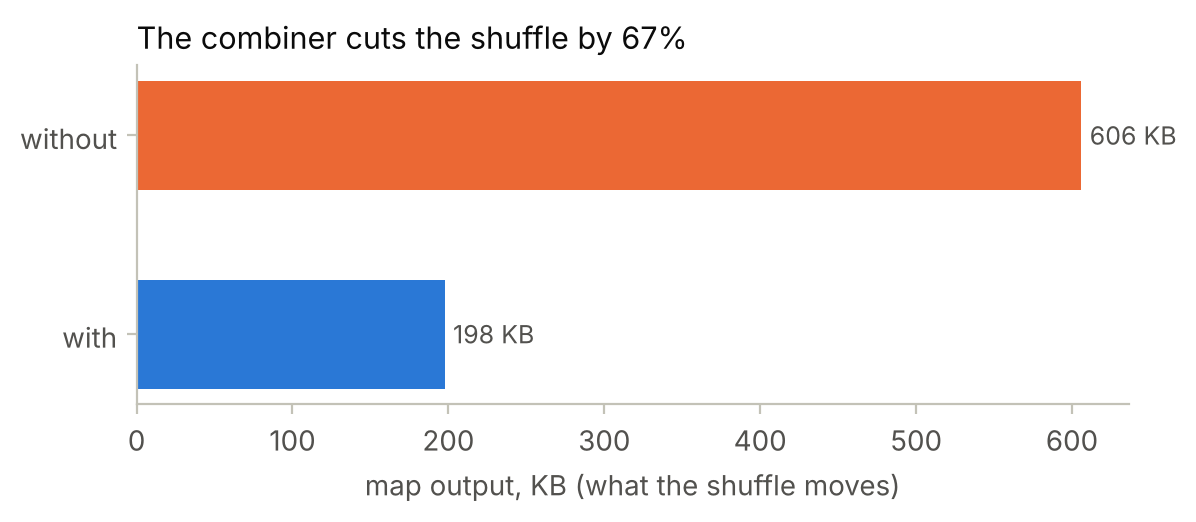

**Figure 2.** Bytes the map tasks emit for word count over the corpus, M = 4, R = 4.

✓ The combiner leaves the output unchanged and cuts map output bytes: by 67%


In [5]:
plain, _ = job(WORDCOUNT, "no-combiner", m=4)
combined, _ = job(Program(mapper=words, reducer=total, combiner=total), "combiner", m=4)
assert output("combiner") == output("no-combiner") == EXPECTED, "the combiner changed the output"
saved = 1 - combined["map.output.bytes"] / plain["map.output.bytes"]
assert saved > 0.5, f"the combiner saved only {saved:.0%}"

table(["", "Without a combiner", "With one"],
      [(name, f"{plain.get(name, 0):,}", f"{combined.get(name, 0):,}")
       for name in ("map.output.records", "map.output.bytes", "reduce.input.records", "reduce.output.records")])
if HAVE_PLOT:
    fig, axis = plt.subplots(figsize=(6.4, 2.2))
    values = [plain["map.output.bytes"] / 1e3, combined["map.output.bytes"] / 1e3]
    bars = axis.barh(["without", "with"], values, color=[ORANGE, BLUE], height=0.55)
    axis.bar_label(bars, labels=[f"{v:,.0f} KB" for v in values], color=INK2, fontsize=9, padding=3)
    axis.invert_yaxis()
    axis.set_xlabel("map output, KB (what the shuffle moves)", color=INK2)
    style(axis, f"The combiner cuts the shuffle by {saved:.0%}")
    plt.show()
    caption(2, "Bytes the map tasks emit for word count over the corpus, M = 4, R = 4.")
passed(5, f"The combiner leaves the output unchanged and cuts map output bytes: by {saved:.0%}")

---

## 6. Counters, parameters and side outputs

Three of the paper's refinements reach user code through `ctx`, the
context every map and reduce call gets. `ctx.params` holds the job's
parameters (the cluster's `mr submit -param name=value`). `ctx.count()`
adds to a named counter that the framework totals across every task and
reports with the job, as §4.9 describes. And `ctx.side_output()` opens an
extra file in the job's output directory (§4.5), which appears only if the
task that wrote it succeeds.

The cell's program counts words at least `min` bytes long, keeps a counter
of the long and short words it saw, and writes each word that occurs only
once to a side file. The counters must add up to every word in the corpus,
and the side files must hold exactly the words whose count is 1.

In [6]:
@mapper
def long_words(ctx, offset, line):
    shortest = int(ctx.params["min"])
    for word in line.split():
        if len(word) >= shortest:
            ctx.count("words.long")
            yield word, b"1"
        else:
            ctx.count("words.short")


@reducer
def tally(ctx, word, counts):
    n = sum(int(c) for c in counts)
    if n == 1:  # a hapax legomenon: a word used once
        ctx.side_output(f"once-{ctx.task.index}.txt").write(word + b"\n")
    yield word, b"%d" % n


counters, _ = job(Program(mapper=long_words, reducer=tally), "context", params={"min": "12"})
once = {w for f in (WORK / "context").glob("once-*.txt") for w in f.read_bytes().split()}
assert counters["words.long"] + counters["words.short"] == sum(COUNTS.values())
assert once == {w for w, n in COUNTS.items() if len(w) >= 12 and n == 1}

names = ("words.long", "words.short", "reduce.output.records")
table(["Counter", "Value"], [(name, f"{counters[name]:,}") for name in names])
side = sorted(p.name for p in (WORK / "context").iterdir())
print("output directory:", ", ".join(side))
print("some words used once:", ", ".join(w.decode() for w in sorted(w for w in once if w.isalpha())[:6]))
passed(6, "User counters add up, a parameter reaches every task, and side outputs hold what they should:"
          f" {len(once):,} words used once")

| Counter | Value |
|---|---|
| words.long | 1,654 |
| words.short | 77,004 |
| reduce.output.records | 1,383 |

output directory: once-0.txt, once-1.txt, once-2.txt, once-3.txt, part-r-00000, part-r-00001, part-r-00002, part-r-00003
some words used once: Andererseits, Angelegenheit, Anstellungen, Arbeitserfolge, Arbeitsunterbrechung, Atemfreiheit
✓ User counters add up, a parameter reaches every task, and side outputs hold what they should: 1,245 words used once


---

## 7. Seven programs, one model

The paper's §2.3 lists the jobs Google wrote in this model, and the
repository ships each as an example, in Go and Python alike: distributed
grep, URL access frequency, the reverse web-link graph, a term vector per
host, an inverted index and a distributed sort, beside word count. They use
the model differently. Grep's reduce is the identity; the inverted index
reduces to a sorted list; the sort replaces the hash partitioner with a
range partitioner on the key's first byte, so the part files, read in
order, are one sorted file (§5.3).

The cell runs each with R = 4 on the inputs and parameters in
`testdata/examples/jobs.json` and compares every part file with the golden
output under `testdata/examples/<program>/expected/r4`.

In [7]:
jobs = json.loads((ROOT / "testdata/examples/jobs.json").read_text())
jobs = {"wordcount": {"inputs": list(CORPUS), "params": {}}, **jobs}
rows = []
for name, setup in jobs.items():
    module = importlib.import_module(f"mapreduce_reloaded.examples.{name}")
    counters, seconds = job(module.program, f"example-{name}", setup["inputs"], params=setup["params"])
    if name == "wordcount":
        assert output(f"example-{name}") == EXPECTED
    else:
        want = sorted((ROOT / f"testdata/examples/{name}/expected/r4").glob("part-r-*"))
        got = parts(f"example-{name}")
        assert [p.name for p in got] == [p.name for p in want], name
        assert all(g.read_bytes() == w.read_bytes() for g, w in zip(got, want, strict=True)), name
    doc = module.__doc__.split("\n", 1)[0]
    rows.append((f"`{name}`", doc.split(", mirroring")[0].removeprefix("The paper's ").rstrip("."),
                 f"{counters['map.input.records']:,}", f"{counters['reduce.output.records']:,}", "✓ matches"))
table(["Program", "What it computes", "Input records", "Output records", "Golden output"], rows)

sort = output("example-distsort").splitlines()
assert sort == sorted(sort), "distsort's parts, read in order, are not one sorted file"
passed(7, f"All {len(jobs)} example programs match their golden output, and distsort's parts concatenate in order")

| Program | What it computes | Input records | Output records | Golden output |
|---|---|---|---|---|
| `wordcount` | word count (§2) | 9,316 | 16,851 | ✓ matches |
| `grep` | distributed grep (§2.3) | 977 | 17 | ✓ matches |
| `invertedindex` | inverted index (§2.3) | 977 | 2,750 | ✓ matches |
| `distsort` | distributed sort (§5.3) | 977 | 977 | ✓ matches |
| `urlfreq` | count of URL access frequency (§2.3) | 2,005 | 903 | ✓ matches |
| `reverselinks` | reverse web-link graph (§2.3) | 2,007 | 1,127 | ✓ matches |
| `termvector` | term vector per host (§2.3) | 724 | 4 | ✓ matches |

✓ All 7 example programs match their golden output, and distsort's parts concatenate in order


---

## 8. The MRKV record format

Between map and reduce, and optionally for a job's input and output, the
system stores records in MRKV, its own binary format (`docs/kv-format.md`).
A file is a header, then blocks of length-prefixed keys and values, then a
footer with the totals. Each block can be compressed with zstd or snappy,
and each carries a CRC-32C checksum, so damage is caught when the block is
read rather than turning into a wrong answer later.

The cell writes section 2's word counts in each codec, reads every file
back, and then flips one byte inside the first block of the uncompressed
file. The reader must refuse it.

| Codec | Bytes | Of uncompressed |
|---|---|---|
| none | 176,066 | 100% |
| zstd | 96,282 | 55% |
| snappy | 134,517 | 76% |

one flipped bit: refused with FormatError('checksum_mismatch: block 0')


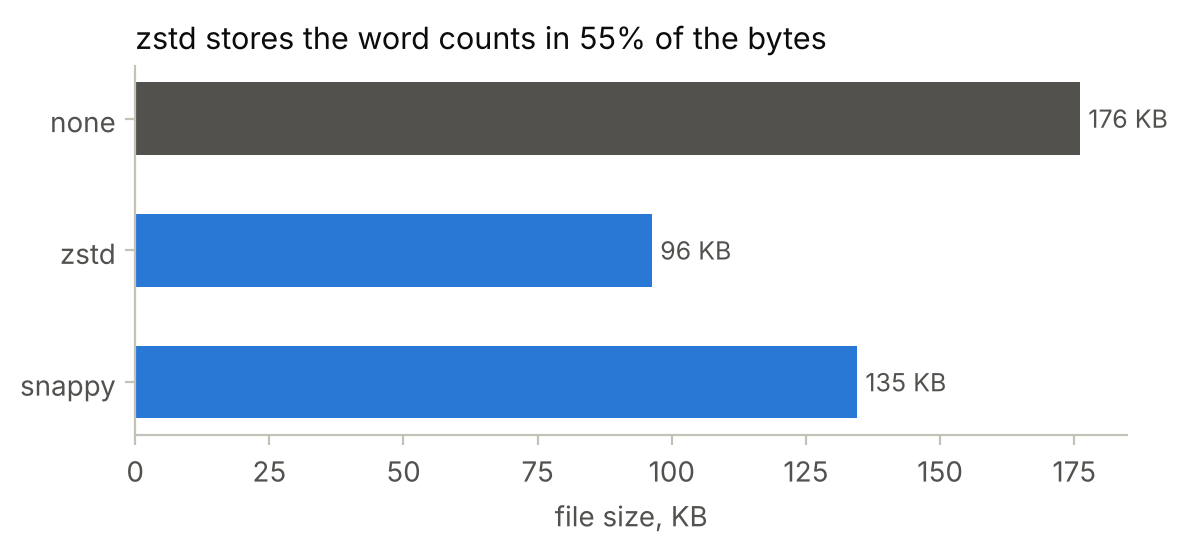

**Figure 3.** The 16,851 word counts from section 2 as MRKV, in each codec.

✓ MRKV round-trips in all three codecs, and a flipped bit fails its block's checksum


In [8]:
records = [tuple(line.rsplit(b"\t", 1)) for line in output("wordcount").splitlines()]
codecs = {"none": kv.CODEC_NONE, "zstd": kv.CODEC_ZSTD, "snappy": kv.CODEC_SNAPPY}
sizes = {}
for name, codec in codecs.items():
    path = WORK / f"counts-{name}.kv"
    with path.open("wb") as f, kv.Writer(f, codec=codec) as writer:
        for key, value in records:
            writer.write(key, value)
    with path.open("rb") as f:
        assert list(kv.read(f)) == records, f"{name} did not read back what was written"
    sizes[name] = path.stat().st_size
table(["Codec", "Bytes", "Of uncompressed"],
      [(name, f"{size:,}", f"{size / sizes['none']:.0%}") for name, size in sizes.items()])

damaged = bytearray((WORK / "counts-none.kv").read_bytes())
damaged[8 + 12 + 100] ^= 0x01  # one bit, inside block 0's payload (after the header and block header)
try:
    list(kv.read(io.BytesIO(bytes(damaged))))
    raise AssertionError("the reader accepted a damaged file")
except kv.FormatError as error:
    assert error.kind == "checksum_mismatch", error
    print(f"one flipped bit: refused with FormatError({str(error)!r})")

if HAVE_PLOT:
    fig, axis = plt.subplots(figsize=(6.4, 2.4))
    values = [sizes[name] / 1e3 for name in codecs]
    bars = axis.barh(list(codecs), values, color=[INK2, BLUE, BLUE], height=0.55)
    axis.bar_label(bars, labels=[f"{v:,.0f} KB" for v in values], color=INK2, fontsize=9, padding=3)
    axis.invert_yaxis()
    axis.set_xlabel("file size, KB", color=INK2)
    style(axis, f"zstd stores the word counts in {sizes['zstd'] / sizes['none']:.0%} of the bytes")
    plt.show()
    caption(3, f"The {len(records):,} word counts from section 2 as MRKV, in each codec.")
passed(8, "MRKV round-trips in all three codecs, and a flipped bit fails its block's checksum")

---

## 9. Sorting more than fits in memory

A reduce task must read its keys in sorted order (§4.2), but its input can
be far larger than its memory, as in the demo's 1 GiB sort. The paper's
§3.1 says that when the intermediate data does not fit in memory, an
external sort is used. Ours is `extsort.Sorter`: it buffers records up
to a memory budget, sorts the buffer and spills it to disk as an MRKV run,
and at the end merges the runs.

The cell feeds it every word of the corpus, one record each, in reading
order, with a budget of half a megabyte, small enough to force several
spills. What comes out must be every record, in key order.

In [9]:
corpus = [p for pattern in CORPUS for p in sorted(ROOT.glob(pattern))]
every_word = [w for path in corpus for w in path.read_bytes().split()]
with extsort.Sorter(dir=str(WORK), budget=512 * 1024) as sorter:
    for i, word in enumerate(every_word):
        sorter.add(word, b"%d" % i)
    result = [key for key, _ in sorter.sorted()]
    runs, spilled = sorter.runs, sorter.spilled_bytes
assert runs > 1, "the budget never forced a spill"
assert result == sorted(every_word), "the merged output is not every record in key order"
table(["Records", "Memory budget", "Runs spilled", "Bytes spilled"],
      [(f"{len(every_word):,}", "512 KiB", runs, f"{spilled:,}")])
passed(9, f"Records sort correctly when they overflow memory: {runs} runs merged")

| Records | Memory budget | Runs spilled | Bytes spilled |
|---|---|---|---|
| 78,658 | 512 KiB | 17 | 909,585 |

✓ Records sort correctly when they overflow memory: 17 runs merged


---

## 10. The write-ahead log

The paper's master is a single point of failure, and its answer is to
abort the job. Ours writes every decision to a write-ahead log before it
acts on it, so a restarted coordinator replays the log and carries on;
the demo's section 11 does that live. The log's rules are what make that
safe. Each record is framed with its length and a CRC-32C. A crash in the
middle of an append leaves a torn last record, which is not a decision
anyone acted on, so opening the log drops it. Damage anywhere before the
last record is different: a decision that was made would be lost, so
opening the log refuses rather than guess.

The cell writes five records, tears a sixth, reopens the log, and then
damages the first record.

In [10]:
CLAIM_10 = "The log drops a torn last record and refuses one damaged before the end"
pending(10, CLAIM_10)  # until every assert below holds, so a failed rerun cannot read as held
path = WORK / "coordinator.wal"
path.unlink(missing_ok=True)  # a rerun starts from an empty log, not the one this cell damaged
path = str(path)
log = wal.Log.open(path, lambda payload: None)
for i in range(5):
    log.append(f"decision {i}".encode())
log.close()
good = os.path.getsize(path)
with open(path, "ab") as f:  # a crash mid-append: a header promising 100 bytes, then 10
    f.write((100).to_bytes(4, "little") + (0).to_bytes(4, "little") + b"x" * 10)

replayed = []
wal.Log.open(path, replayed.append).close()
assert replayed == [f"decision {i}".encode() for i in range(5)]
assert os.path.getsize(path) == good, "the torn record was not removed"
print(f"torn tail: replayed {len(replayed)} records; the file is back to {good} bytes")

with open(path, "r+b") as f:  # one bit in the first record's payload
    f.seek(8)
    byte = f.read(1)
    f.seek(8)
    f.write(bytes([byte[0] ^ 0x01]))
try:
    wal.Log.open(path, lambda payload: None).close()
    raise AssertionError("the log opened despite a damaged record")
except wal.CorruptError as error:
    print(f"damage before the end: refused with CorruptError({str(error)!r})")
passed(10, CLAIM_10)

torn tail: replayed 5 records; the file is back to 90 bytes
damage before the end: refused with CorruptError('wal: corrupt record at offset 0')
✓ The log drops a torn last record and refuses one damaged before the end


---

## 11. Go and Python agree

The system is two implementations of one design: the Go coordinator,
workers and `mr` client, and this Python library, which runs the same
programs on the same formats. They are tested against each other. The cell
runs word count three ways: the Go client's built-in program with
`mr run -local`, the Go client again on `examples/wordcount.go`, a job file
of plain Go that the client interprets rather than compiles (ADR 0015),
and the Python run from section 3. All three must write the same bytes and
report the same counters.

In [11]:
MR = ROOT / "bin" / "mr"
if not MR.exists() and BUILD_MR and shutil.which("go"):
    MR = WORK / "mr"  # built for this run, removed with it
    subprocess.run(["go", "build", "-o", str(MR), "./cmd/mr"], cwd=ROOT / "go", check=True)
if not MR.exists():
    skipped(11, "Go, a Go job file and Python give byte-identical output", "no bin/mr and no Go to build it")
else:
    python_counters, _ = job(wordcount, "python", m=4)
    rows = [("Python, `mapreduce_reloaded.examples.wordcount`", f"{len(python_counters)} counters, the reference")]
    for label, program in (("Go, built-in `wordcount`", "wordcount"),
                           ("Go, job file `examples/wordcount.go`", "examples/wordcount.go")):
        out = WORK / ("go-" + program.replace("/", "-"))
        result = subprocess.run([str(MR), "run", "-local", "-m", "4", "-r", "4", program, str(out), *CORPUS],
                             cwd=ROOT, capture_output=True, text=True, check=True)
        # mr run prints the job's counters to stderr, one "name<TAB>value" a line
        go_counters = {k: int(v) for k, v in (line.split("\t") for line in result.stderr.splitlines())}
        assert b"".join(p.read_bytes() for p in sorted(out.glob("part-r-*"))) == output("python") == EXPECTED
        assert go_counters == python_counters, f"{label}: counters differ"
        rows.append((label, f"{len(go_counters)} counters, all equal"))
    table(["Run", "Counters against Python"], rows)
    passed(11, "Go, a Go job file and Python give byte-identical output and equal counters")

| Run | Counters against Python |
|---|---|
| Python, `mapreduce_reloaded.examples.wordcount` | 9 counters, the reference |
| Go, built-in `wordcount` | 9 counters, all equal |
| Go, job file `examples/wordcount.go` | 9 counters, all equal |

✓ Go, a Go job file and Python give byte-identical output and equal counters


---

## 12. Scorecard

Every claim this run checked, in section order. A section that could not
run here, such as section 11 without Go, shows as skipped, so the table
never claims more than ran. The cell after it removes the temporary
directory and everything in it.

In [12]:
rows = sorted(CHECKS.items(), key=lambda item: item[0][0])  # by section, then in the order checked
table(["§", "Claim", "Result"], [(section, claim, result) for (section, _), (claim, result) in rows])
held = sum(result.startswith("✓") for _, result in CHECKS.values())
print(f"{held} of {len(CHECKS)} claims held on this machine today.")

| § | Claim | Result |
|---|---|---|
| 2 | Two functions count 16,851 distinct words and match the golden output: 0.45 s | ✓ held |
| 3 | Requested M = 1, 4 and 16 give byte-identical output | ✓ held |
| 4 | Every key is in part hash(key) mod R, and every part is sorted: largest part / smallest = 1.01 | ✓ held |
| 5 | The combiner leaves the output unchanged and cuts map output bytes: by 67% | ✓ held |
| 6 | User counters add up, a parameter reaches every task, and side outputs hold what they should: 1,245 words used once | ✓ held |
| 7 | All 7 example programs match their golden output, and distsort's parts concatenate in order | ✓ held |
| 8 | MRKV round-trips in all three codecs, and a flipped bit fails its block's checksum | ✓ held |
| 9 | Records sort correctly when they overflow memory: 17 runs merged | ✓ held |
| 10 | The log drops a torn last record and refuses one damaged before the end | ✓ held |
| 11 | Go, a Go job file and Python give byte-identical output and equal counters | ✓ held |

10 of 10 claims held on this machine today.


In [13]:
shutil.rmtree(WORK, ignore_errors=True)
print("removed this run's temporary directory")

removed this run's temporary directory
